In [3]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import os
from ast import literal_eval
from collections import Counter
import math
import numpy as np
import seaborn as sns

In [4]:
username = os.path.expanduser('~')
username

'/home/ehdgus7279'

In [13]:
benchmarks = [
    'gups',    
    'syr2k',
    'gpt3_gemm',
    'llama3_gemm',
    'gaussian',
    # 'gramschmidt',
    'vgg16',
    'lenet',
    'spmv',
    'mis',
    'stencil2d',
    'gpt3_mm',
    'llama3_mm',
    'matrixtranspose',
    'bfs',
    'kmeans',
    'lud',
    'gemver',
    'atax',
    'mvt',
    'bicg',
    'bptree',

    "fdtd2d",
    "jacobi1d",
    "fastwalshtransform",
    "relu",
    "fft",
    "fir",
    "sssp",
    "convolution2d",
    "color",
    "bitonicsort",
    "pagerank",
    "simpleconvolution",
]

In [6]:
num_chiplets = 36

In [7]:
def get_xy_routing_path(src_id, dst_id, width=6):
    """
    6x6 Mesh에서 XY-Routing 경로를 반환합니다.
    노드 ID는 0부터 35까지, 행 우선(Row-major) 순서입니다.
    """
    # 1. 좌표 변환 (ID -> (x, y))
    src_x, src_y = src_id % width, src_id // width
    dst_x, dst_y = dst_id % width, dst_id // width
    
    path = []
    
    # 2. X축 이동 (가로)
    # src_x에서 dst_x까지 이동
    step_x = 1 if dst_x >= src_x else -1
    # range의 끝은 포함되지 않으므로 +step_x
    for x in range(src_x, dst_x + step_x, step_x):
        path.append(src_y * width + x)
        
    # 3. Y축 이동 (세로)
    # 이미 path의 마지막 요소는 (dst_x, src_y) 위치임.
    # src_y에서 dst_y까지 이동하되, 시작점(src_y)은 이미 포함되었으므로 제외
    step_y = 1 if dst_y >= src_y else -1
    
    # Y축 이동이 필요한 경우에만 실행
    if src_y != dst_y:
        for y in range(src_y + step_y, dst_y + step_y, step_y):
            path.append(y * width + dst_x)
            
    return path

In [8]:
base_dir=f'{username}/mgvm/results/reports'
sub_dir = "20260407-001102-mesh"
platform = "mesh"
report_dir = f'{base_dir}/{sub_dir}'
print(report_dir)

/home/ehdgus7279/mgvm/results/reports/20260407-001102-mesh


In [9]:
"""
traffic 집중되는 칩렛 
"""
report_dir = f'{base_dir}/{sub_dir}'
result_dir = f'{report_dir}/c2c'

if not os.path.isdir(f'{result_dir}'):
    os.makedirs(f'{result_dir}', exist_ok=True, mode=0o777)

for benchmark in benchmarks:
    report_file = f"{report_dir}/{benchmark}_{platform}_6x6.csv"
    
    if not os.path.exists(report_file):
        print(f"  Skip: No file {report_file}")
        continue

    df = pd.read_csv(
        report_file,
        skipinitialspace=True,
    )

    df = df[df['where']=='Chip-to-chip-traced']
    c2c_df = df[df['what'].str.contains(r'^\d+-\d+$', regex=True, na=False)]

    c2c_df[[
        'src',
        'dst',
    ]] = c2c_df['what'].str.split('-',expand=True)

    c2c_df['src'] = c2c_df['src'].astype(int)
    c2c_df['dst'] = c2c_df['dst'].astype(int)
    c2c_df = c2c_df.groupby('dst')['value'].sum().reset_index()
    c2c_df = c2c_df.drop(columns=['dst']) # 인덱스와 중복
    c2c_df = c2c_df.reindex(range(36), fill_value=0)

    c2c_df.to_csv(f"{result_dir}/{benchmark}_c2c_6x6.csv")

  Skip: No file /home/ehdgus7279/mgvm/results/reports/20260329-231119-dynamicdist/fdtd2d_dynamicdist_6x6.csv
  Skip: No file /home/ehdgus7279/mgvm/results/reports/20260329-231119-dynamicdist/jacobi1d_dynamicdist_6x6.csv
  Skip: No file /home/ehdgus7279/mgvm/results/reports/20260329-231119-dynamicdist/fastwalshtransform_dynamicdist_6x6.csv
  Skip: No file /home/ehdgus7279/mgvm/results/reports/20260329-231119-dynamicdist/relu_dynamicdist_6x6.csv
  Skip: No file /home/ehdgus7279/mgvm/results/reports/20260329-231119-dynamicdist/fft_dynamicdist_6x6.csv
  Skip: No file /home/ehdgus7279/mgvm/results/reports/20260329-231119-dynamicdist/fir_dynamicdist_6x6.csv
  Skip: No file /home/ehdgus7279/mgvm/results/reports/20260329-231119-dynamicdist/sssp_dynamicdist_6x6.csv
  Skip: No file /home/ehdgus7279/mgvm/results/reports/20260329-231119-dynamicdist/convolution2d_dynamicdist_6x6.csv
  Skip: No file /home/ehdgus7279/mgvm/results/reports/20260329-231119-dynamicdist/color_dynamicdist_6x6.csv
  Skip: N

In [ ]:
"""
벤치마크 별 dst 칩렛이 처리하는 요청 수에 대한 std
"""
report_dir = f'{base_dir}/{sub_dir}'
result_dir = f'{report_dir}/c2c'

if not os.path.isdir(f'{result_dir}'):
    os.makedirs(f'{result_dir}', exist_ok=True, mode=0o777)

for benchmark in benchmarks:
    report_file = f"{report_dir}/{benchmark}_{platform}_6x6.csv"
    
    if not os.path.exists(report_file):
        print(f"  Skip: No file {report_file}")
        continue

    df = pd.read_csv(
        report_file,
        skipinitialspace=True,
    )

    c2c_df = df[df['what'].str.contains(r'^\d+-\d+$', regex=True, na=False)]

    c2c_df[[
        'src',
        'dst',
    ]] = c2c_df['what'].str.split('-',expand=True)

    c2c_df['src'] = c2c_df['src'].astype(int)
    c2c_df['dst'] = c2c_df['dst'].astype(int)
    grouped_df = c2c_df.groupby('dst')['value'].sum()
    grouped_df = grouped_df.reindex(range(36), fill_value=0)

    mean_value = grouped_df.mean()
    std_value = grouped_df.std()
    print(f"{benchmark}\t{mean_value}\t{std_value}")

fdtd2d	78809.36111111111	59354.36599714478
jacobi1d	10039.0	6921.7194932225575
fastwalshtransform	151.69444444444446	329.48026773298096
relu	4204.111111111111	2981.0689815929913
fft	834.5555555555555	634.9297573947821
fir	4338.972222222223	3260.8383890046357
sssp	1787.7777777777778	1807.624188361399
convolution2d	65757.69444444444	44227.537444976806
color	792.7222222222222	655.0286628891512
bitonicsort	13467.861111111111	10075.790527377358
pagerank	5250.138888888889	4842.795745982024
simpleconvolution	2449.0555555555557	833.9986277633262
  Skip: No file /home/ehdgus7279/mgvm/results/reports/mesh/gups_mesh_6x6.csv
syr2k	43592.444444444445	176877.13211677186
spmv	1117399.6666666667	71412.94406638457
mis	484112.05555555556	60170.66166446636
stencil2d	337491.75	223116.69135171335
gemm	127401.63888888889	518198.1702158328
lu	31936.5	22679.43247526269
matrixmultiplication	40675.52777777778	80242.01053010505
mm2	9706.555555555555	58239.33333333332
mm3	76135.19444444444	340116.6281541687
gauss

In [18]:
"""
c2c_df 모두 병합
"""

result_df=pd.DataFrame()

dfs_to_concat = []

for benchmark in benchmarks:
    report_file = f"{result_dir}/{benchmark}_c2c_6x6.csv"
    
    if not os.path.exists(report_file):
        print(f"  Skip: No file {report_file}")
        continue

    # 1. CSV 읽기 (첫 번째 열이 인덱스처럼 보이므로 index_col=0 지정)
    df = pd.read_csv(report_file, index_col=0, skipinitialspace=True)
    
    # 2. 'value' 컬럼 이름을 현재 벤치마크 이름으로 변경
    df = df.rename(columns={'value': benchmark})
    
    # 3. 리스트에 저장
    dfs_to_concat.append(df)

# 4. 리스트에 모인 DataFrame들을 컬럼 방향(axis=1)으로 병합
if dfs_to_concat:
    result_df = pd.concat(dfs_to_concat, axis=1)
    result_df = result_df.reindex(range(36), fill_value=0)
    result_df = result_df.fillna(0)
    result_df.to_csv(f"{result_dir}/all_c2c_6x6.csv")

  Skip: No file /home/ehdgus7279/mgvm/results/reports/mesh/c2c/gups_c2c_6x6.csv


Skip: No file /home/ehdgus7279/mgvm/results/reports/mesh/c2c/gups_c2c_6x6.csv


/tmp/ipykernel_1435499/3627794070.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(


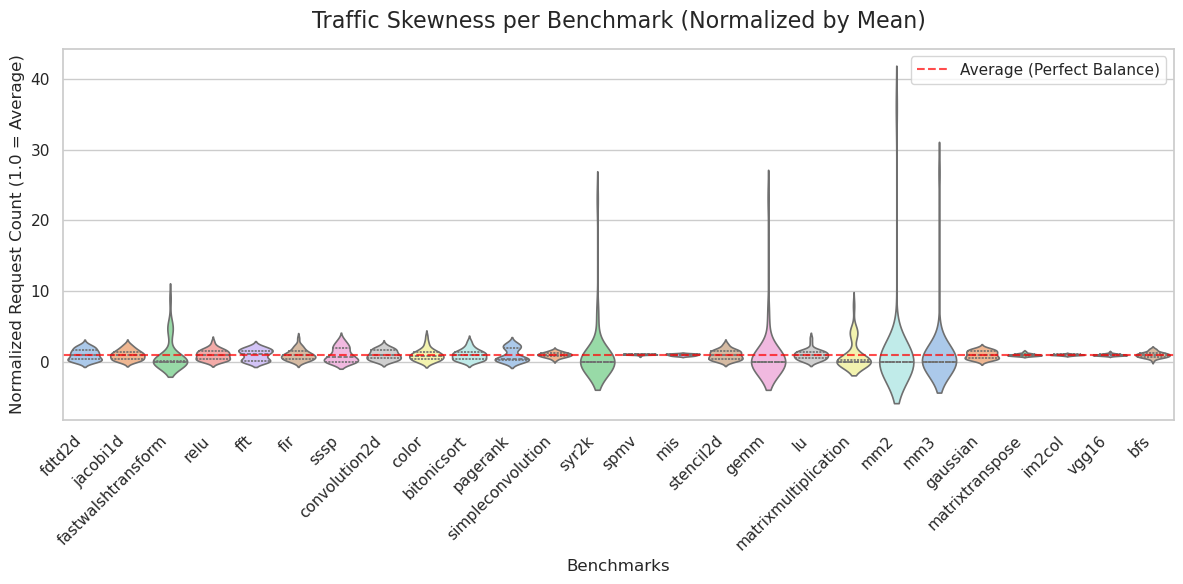

In [14]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ----------------------------------------------------
# 1. 환경 설정 및 데이터 병합 (Long Format)
# ----------------------------------------------------

dfs_to_concat = []

for benchmark in benchmarks:
    report_file = f"{result_dir}/{benchmark}_c2c_6x6.csv"
    
    if not os.path.exists(report_file):
        print(f"Skip: No file {report_file}")
        continue

    # CSV 읽기 (skipinitialspace=True 유지)
    df = pd.read_csv(report_file, skipinitialspace=True)
    
    # Seaborn에서 그리기 쉽게 벤치마크 이름 컬럼 추가
    df['benchmark'] = benchmark
    
    # [수정된 로직] 스케일 차이 해결을 위해 정규화(Normalization) 수행
    # 각 칩렛의 value를 해당 벤치마크의 전체 평균값으로 나눔
    mean_val = df['value'].mean()
    if mean_val > 0:
        df['normalized_value'] = df['value'] / mean_val
    else:
        df['normalized_value'] = 0  # 트래픽이 아예 없는 경우 방어코드
    
    # 'benchmark'와 정규화된 컬럼만 리스트에 추가
    if 'normalized_value' in df.columns:
        dfs_to_concat.append(df[['benchmark', 'normalized_value']])

# 데이터프레임 위아래로 병합
if dfs_to_concat:
    result_df = pd.concat(dfs_to_concat, axis=0, ignore_index=True)
    result_df = result_df.fillna(0)
    
    # ----------------------------------------------------
    # 2. 바이올린 플롯 (Violin Plot) 시각화
    # ----------------------------------------------------
    
    # 그래프 크기 및 해상도 설정
    plt.figure(figsize=(12, 6), dpi=100)
    
    # Seaborn 테마 설정
    sns.set_theme(style="whitegrid")
    
    # 바이올린 플롯 그리기 (y값을 normalized_value로 변경)
    ax = sns.violinplot(
        data=result_df, 
        x='benchmark', 
        y='normalized_value', 
        palette='pastel',    
        inner='quartile',    
        linewidth=1.2        
    )
    
    # [추가된 로직] 완벽한 균형 상태를 의미하는 1.0(평균) 위치에 빨간 점선 추가
    plt.axhline(y=1.0, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='Average (Perfect Balance)')
    plt.legend()
    
    # 제목 및 축 이름 설정
    plt.title('Traffic Skewness per Benchmark (Normalized by Mean)', fontsize=16, pad=15)
    plt.xlabel('Benchmarks', fontsize=12)
    # Y축 설명을 정규화된 값이라는 것을 명확히 표시
    plt.ylabel('Normalized Request Count (1.0 = Average)', fontsize=12)
    
    # X축 벤치마크 이름 회전
    plt.xticks(rotation=45, ha='right')
    
    # 여백 자동 조절
    plt.tight_layout()
    
    # 파일, 디렉터리 이름 원본 유지
    plt.savefig(f'{result_dir}/c2c_violin_plot.png', format='png', dpi=300)
    
    # 화면에 출력
    plt.show()

else:
    print("병합할 데이터가 없어서 그래프를 그릴 수 없습니다.")

In [ ]:
"""
트래픽 히트맵
"""

base_dir=f'{username}/mgvm/results/reports'
# sub_dir = "20260327-211410-dynamicdist"
# sub_dir = "20260329-231119-dynamicdist"
sub_dir = "20260407-001102-mesh"
platform = "mesh"
report_dir = f'{base_dir}/{sub_dir}'
print(report_dir)
    
for benchmark in benchmarks:
    
    report_file = f"{report_dir}/{benchmark}_{platform}_6x6.csv"

    if not os.path.exists(report_file):
        print(f"  Skip: No file {report_file}")
        continue
    else:
        print(f"Processing {benchmark}")

    result_dir = f'{report_dir}/heatmap/{benchmark}'
    if not os.path.isdir(f'{result_dir}'):
        os.makedirs(f'{result_dir}', exist_ok=True, mode=0o777)
    
    df = pd.read_csv(
        report_file,
        skipinitialspace=True,
        on_bad_lines='skip')
    df = df[df['where']=='Chip-to-chip-traced']

    c2c_df = df[df['what'].str.contains(r'^\d+-\d+$', regex=True, na=False)]

    c2c_df[[
        'src',
        'dst',
    ]] = c2c_df['what'].str.split('-',expand=True)

    c2c_df['src'] = c2c_df['src'].astype(int)
    c2c_df['dst'] = c2c_df['dst'].astype(int)
    
    c2c_df['path'] = c2c_df.apply(
        lambda row: get_xy_routing_path(row['src'], row['dst']), 
        axis=1
    )
            
    mesh_size = 6
    heatmap_matrix = np.zeros((mesh_size, mesh_size))

    for index, row in c2c_df.iterrows():
        path_nodes = row['path']  # 예: [0, 1, 2]
        count = row['value']      # 예: 100

        for node_id in path_nodes:
            r = int(node_id // mesh_size)
            c = int(node_id % mesh_size)

            # 해당 좌표에 카운트 누적
            heatmap_matrix[r, c] += float(count)

    # 4. 시각화 (Seaborn Heatmap)
    plt.figure(figsize=(10, 8))
    sns.set(font_scale=1.2)

    ax = sns.heatmap(
        heatmap_matrix, 
        annot=False,       # 숫자 표시 여부
        fmt='.0f',        # 소수점 제거
        cmap='Reds',      # 색상 테마 (빨간색)
        linewidths=.5,    # 셀 간격
        cbar_kws={'label': 'Accumulated Access Count'}
    )

    # 축 레이블 설정 (0~5)
    ax.set_xticklabels(range(mesh_size))
    ax.set_yticklabels(range(mesh_size))

    plt.title('Chiplet Access Heatmap (Path Accumulation)', fontsize=16, pad=20)
    plt.xlabel('Column (X)', fontsize=14)
    plt.ylabel('Row (Y)', fontsize=14)
    
    plt.savefig(f'{result_dir}/{benchmark}_heatmap')
    plt.close()

/home/ehdgus7279/mgvm/results/reports/20260407-001102-mesh
Processing gups
0 0 100664.0
0 1 100664.0
0 0 100116.0
0 1 100116.0
0 2 100116.0
0 0 100393.0
0 1 100393.0
0 2 100393.0
0 3 100393.0
0 0 99437.0
0 1 99437.0
0 2 99437.0
0 3 99437.0
0 4 99437.0
0 0 101032.0
0 1 101032.0
0 2 101032.0
0 3 101032.0
0 4 101032.0
0 5 101032.0
0 0 100347.0
1 0 100347.0
0 0 19907.0
0 1 19907.0
1 1 19907.0
0 0 19124.0
0 1 19124.0
0 2 19124.0
0 3 19124.0
0 4 19124.0
1 4 19124.0
2 4 19124.0
3 4 19124.0
4 4 19124.0
0 0 90963.0
0 1 90963.0
0 2 90963.0
0 3 90963.0
0 4 90963.0
0 5 90963.0
1 5 90963.0
2 5 90963.0
3 5 90963.0
4 5 90963.0
0 0 91294.0
1 0 91294.0
2 0 91294.0
3 0 91294.0
4 0 91294.0
5 0 91294.0
0 0 91392.0
0 1 91392.0
1 1 91392.0
2 1 91392.0
3 1 91392.0
4 1 91392.0
5 1 91392.0
0 0 91843.0
0 1 91843.0
0 2 91843.0
1 2 91843.0
2 2 91843.0
3 2 91843.0
4 2 91843.0
5 2 91843.0
0 0 91502.0
0 1 91502.0
0 2 91502.0
0 3 91502.0
1 3 91502.0
2 3 91502.0
3 3 91502.0
4 3 91502.0
5 3 91502.0
0 0 90763.0
0 1 9076

In [ ]:
"""
홉 별 경로 히트맵
"""

report_dir = f'{base_dir}/{sub_dir}'
    
for benchmark in benchmarks:
    report_file = f"{report_dir}/{benchmark}_{platform}_6x6.csv"

    if not os.path.exists(report_file):
        print(f"  Skip: No file {report_file}")
        continue

    result_dir = f'{report_dir}/heatmap/{benchmark}'
    if not os.path.isdir(f'{result_dir}'):
        os.makedirs(f'{result_dir}', exist_ok=True, mode=0o777)
        
    df = pd.read_csv(
        report_file,
        skipinitialspace=True,
        on_bad_lines='skip')

    c2c_df = df[df['what'].str.contains(r'^\d+-\d+$', regex=True, na=False)]

    c2c_df[[
        'src',
        'dst',
    ]] = c2c_df['what'].str.split('-',expand=True)

    c2c_df['src'] = c2c_df['src'].astype(int)
    c2c_df['dst'] = c2c_df['dst'].astype(int)

    c2c_df['path'] = c2c_df.apply(
        lambda row: get_xy_routing_path(row['src'], row['dst']), 
        axis=1
    )

    c2c_df['hops'] = c2c_df['path'].str.len() - 1

    for h in range(1, 11):

        mesh_size = 6
        heatmap_matrix = np.zeros((mesh_size, mesh_size))
        hop_df = c2c_df[c2c_df['hops']==h]

        for index, row in hop_df.iterrows():
            path_nodes = row['path']  # 예: [0, 1, 2]
            count = row['value']      # 예: 100
            
            for node_id in path_nodes:
                r = node_id // mesh_size
                c = node_id % mesh_size
                
                # 해당 좌표에 카운트 누적
                heatmap_matrix[r, c] += count

        # 4. 시각화 (Seaborn Heatmap)
        plt.figure(figsize=(10, 8))
        sns.set(font_scale=1.2)

        ax = sns.heatmap(
            heatmap_matrix, 
            annot=True,       # 숫자 표시 여부
            fmt='.0f',        # 소수점 제거
            cmap='Reds',      # 색상 테마 (빨간색)
            linewidths=.5,    # 셀 간격
            cbar_kws={'label': 'Accumulated Access Count'}
        )

        # 축 레이블 설정 (0~5)
        ax.set_xticklabels(range(mesh_size))
        ax.set_yticklabels(range(mesh_size))

        plt.title('Chiplet Access Heatmap (Path Accumulation)', fontsize=16, pad=20)
        plt.xlabel('Column (X)', fontsize=14)
        plt.ylabel('Row (Y)', fontsize=14)

        plt.show()
        # plt.savefig(f'{result_dir}/{benchmark}_routing_path_heatmap_per_hop_{h}')
        plt.close() 